# Final Project — SMS Spam Detection

**Denis Shin · Abylay Latiyev · Nikita Vassilenko**

Run all cells in order from this notebook's folder with the requirements installed. The notebook reads the bundled UCI corpus or downloads the same verified file if it is absent. It writes the benchmark and demo checkpoint locally.

Dataset: [UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) (5,574 English SMS, `ham` / `spam`, CC BY 4.0), stored in `data/SMSSpamCollection`.

| Part | Scope |
|---|---|
| 1 — Data & classical ML | loading, deduplication, shared split, EDA, preprocessing, meta-features, classical models |
| 2 — Deep learning | neural models / transformers, weighted loss, threshold tuning |
| 3 — Evaluation & demo | team benchmark, error analysis, demo |

The main metric is F1 for the `spam` class. We also report Precision, because blocking a personal message is costly, and PR-AUC for ranking quality. With about 13% spam, accuracy says little.

For the defense, see **2.6** for neural learning curves, **3.1** for the shared benchmark, **3.3** for errors and **3.4** for predictions on new SMS. References and AI disclosure are at the end.

## Part 1 — Data, Features & Classical ML

### 1.0 Problem formulation

Spam SMS carries prize scams, premium-rate numbers and phishing links, and people cannot check every sender themselves. A filter has to catch it without hiding personal messages, because losing a message from a friend costs the user more than seeing one more advert.

- Task: binary text classification, `ham` (0) vs `spam` (1).
- Input: the raw text of one SMS. Part 1 models also get 9 hand-crafted meta-features derived from that text.
- Output: a label and a spam score (probability, or decision score for LinearSVC).
- Data: UCI SMS Spam Collection, 5,574 real English SMS, CC BY 4.0 (use with attribution).
- Success: F1 for spam on the held-out test set, well above the `DummyClassifier` baselines. We want Precision above about 0.95, so that fewer than 1 in 20 flagged messages is personal. PR-AUC shows whether the ranking holds across thresholds.

In [1]:
import csv, re
from collections import Counter
from functools import lru_cache
from hashlib import sha256
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             PrecisionRecallDisplay, ConfusionMatrixDisplay)

SEED = 42
DATA, ART = Path("data"), Path("artifacts")
OUT = ART / "participant1"
OUT.mkdir(parents=True, exist_ok=True)
try:
    STOP = set(stopwords.words("english"))
except LookupError:
    nltk.download("stopwords", quiet=True)
    STOP = set(stopwords.words("english"))

### 1.1 Loading and deduplication

The UCI corpus contains two fields per row, the `ham` or `spam` label and the SMS text. The collection combines sources including the NUS SMS Corpus and publicly reported spam from a UK forum. The source collections overlap, so it contains repeated messages (Gómez Hidalgo et al., 2012). A duplicate left in place can land in both train and test and inflate everyone's scores. Before splitting we lower-case the text, collapse whitespace and keep the first copy of each message.

In [2]:
raw_path = DATA / "SMSSpamCollection"
raw_sha256 = "7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d"
if not raw_path.exists():
    uci_zip = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
    with urlopen(uci_zip, timeout=30) as response, ZipFile(BytesIO(response.read())) as archive:
        corpus = archive.read("SMSSpamCollection")
    if sha256(corpus).hexdigest() != raw_sha256:
        raise ValueError("The UCI download differs from the verified project dataset.")
    raw_path.parent.mkdir(parents=True, exist_ok=True)
    raw_path.write_bytes(corpus)

raw = pd.read_csv(raw_path, sep="\t", header=None, names=["label", "text"],
                  quoting=csv.QUOTE_NONE, encoding="utf-8")

def norm_key(s: pd.Series) -> pd.Series:
    return s.str.lower().str.split().str.join(" ")

print("missing values:", raw.isna().sum().to_dict(), " empty texts:", (raw.text.str.strip() == "").sum())
raw["key"] = norm_key(raw.text)
conflicts = raw.groupby("key").label.nunique().gt(1).sum()
df = raw.drop_duplicates("key").drop(columns="key").reset_index(drop=True)
df.insert(0, "idx", df.index)
df["y"] = (df.label == "spam").astype(int)

print(f"raw: {len(raw)}  after dedup: {len(df)}  removed: {len(raw) - len(df)}  label conflicts: {conflicts}")
print(df.label.value_counts().to_string())

missing values: {'label': 0, 'text': 0}  empty texts: 0
raw: 5574  after dedup: 5159  removed: 415  label conflicts: 0
label
ham     4517
spam     642


### 1.2 Shared split (train / val / test = 70 / 10 / 20, stratified, seed 42)

The split is made once and saved to `artifacts/split.csv`. Part 1 tunes with 5-fold CV on train+val. Part 2 uses `val` for early stopping and threshold tuning. `test` is used only for the final evaluation.

In [3]:
def make_split(y: np.ndarray, seed: int = SEED) -> pd.Series:
    idx = np.arange(len(y))
    rest, te = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
    tr, va = train_test_split(rest, test_size=0.125, stratify=y[rest], random_state=seed)
    s = pd.Series("train", index=idx, name="split")
    s[va], s[te] = "val", "test"
    return s

split = make_split(df.y.values)
df[["idx", "label", "text"]].to_csv(DATA / "sms_dedup.csv", index=False)
split.rename_axis("idx").reset_index().to_csv(ART / "split.csv", index=False)

tr, va, te = (split == "train").values, (split == "val").values, (split == "test").values
trva = tr | va
pd.DataFrame({"n": split.value_counts(), "spam_share": df.y.groupby(split).mean().round(4)})

,n,spam_share
split,,
test,1032,0.1240
train,3611,0.1246
val,516,0.1240


In [4]:
# checks: dedup, reproducibility, proportions, stratification
assert norm_key(pd.Series(["Hi  there "]))[0] == norm_key(pd.Series(["hi there"]))[0]
assert not norm_key(df.text).duplicated().any()
assert make_split(df.y.values).equals(split)
for name, share in {"train": .7, "val": .1, "test": .2}.items():
    assert abs((split == name).mean() - share) < 0.01, name
    assert abs(df.y[split == name].mean() - df.y.mean()) < 0.01, name
assert pd.read_csv(ART / "split.csv").split.equals(split.reset_index(drop=True))

### 1.3 EDA and meta-features

EDA uses the train split only, so the test set does not influence feature design.

In [5]:
URL = r"https?://|www\.|\b\w+\.(?:com|co\.uk|net|org)\b"
PHONE = r"\b\d{5,}\b"
CURR = r"[£$€]"
def meta_features(texts: pd.Series) -> pd.DataFrame:
    letters = texts.str.count(r"[A-Za-z]").clip(lower=1)
    n, digits = texts.str.len(), texts.str.count(r"\d")
    return pd.DataFrame({
        "n_chars": n,
        "n_words": texts.str.split().str.len(),
        "upper_ratio": texts.str.count(r"[A-Z]") / letters,
        "digit_ratio": digits / n.clip(lower=1),
        "n_digits": digits,
        "has_url": texts.str.contains(URL, case=False).astype(int),
        "has_phone": texts.str.contains(PHONE).astype(int),
        "has_currency": texts.str.contains(CURR).astype(int),
        "n_exclaim": texts.str.count("!"),
    }, index=texts.index)

META = list(meta_features(pd.Series(["x"])).columns)

m = meta_features(pd.Series(["WIN £1000 call 09061701461 www.x.com", "ok"]))
assert m.loc[0, ["has_url", "has_phone", "has_currency"]].tolist() == [1, 1, 1] and m.loc[0, "upper_ratio"] > 0
assert m.loc[1, ["has_url", "has_phone", "has_currency", "n_exclaim"]].sum() == 0

df = df.join(meta_features(df.text))

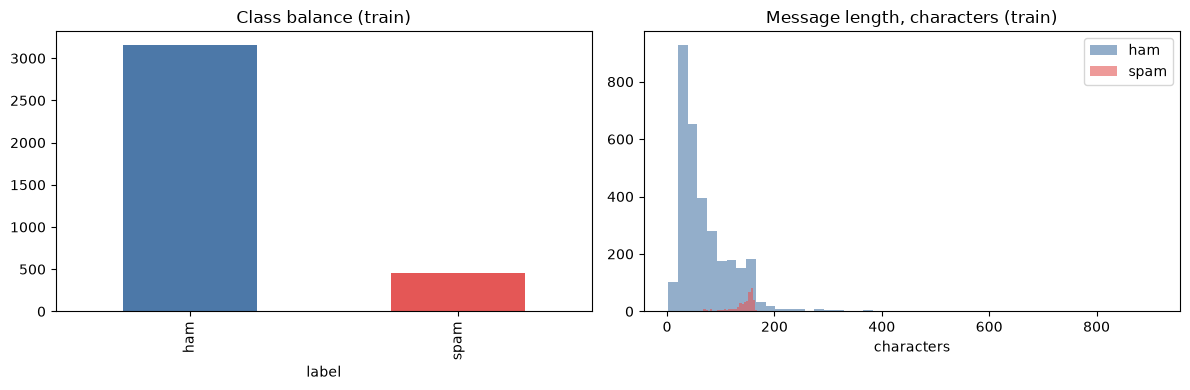

label,ham,spam
n_chars,71.267,137.353
n_words,14.308,23.691
upper_ratio,0.078,0.162
digit_ratio,0.005,0.113
n_digits,0.309,15.171
has_url,0.003,0.187
has_phone,0.001,0.720
has_currency,0.004,0.358
n_exclaim,0.189,0.676


In [6]:
train = df[tr]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
train.label.value_counts().plot.bar(ax=ax[0], color=["#4C78A8", "#E45756"], title="Class balance (train)")
for lab, c in [("ham", "#4C78A8"), ("spam", "#E45756")]:
    ax[1].hist(train.n_chars[train.label == lab], bins=50, alpha=.6, label=lab, color=c)
ax[1].set(title="Message length, characters (train)", xlabel="characters"); ax[1].legend()
plt.tight_layout(); plt.show()

train.groupby("label")[META].mean().T.round(3)

In [7]:
# length outliers (train): the long tail is real messages, not errors
q = train.groupby("label").n_chars.describe(percentiles=[.5, .95, .99]).round(0)
print(q[["50%", "95%", "99%", "max"]])
train.loc[train.n_chars.nlargest(3).index, ["label", "n_chars", "text"]]

         50%    95%    99%    max
label                            
ham     53.0  158.0  256.0  910.0
spam   149.0  162.0  174.0  223.0


,label,n_chars,text
1058,ham,910,For me the love should start with attraction.i...
1799,ham,790,The last thing i ever wanted to do was hurt yo...
2330,ham,629,Indians r poor but India is not a poor country...


On train, 12.5% of messages are spam. Spam is about twice as long as ham (137 vs 71 characters on average) and has many more digits from phone numbers, short codes and prices. It also contains currency symbols, URLs and capital letters more often. The models get these meta-features alongside the text.

The raw file has no missing labels and no empty messages. Lengths are right-skewed, and ham has the long tail: its 99th percentile is 256 characters and the longest message, a multi-part personal one, has 910. No spam message is longer than 223. We keep the long messages because they are genuine. Linear models get the lengths through `StandardScaler`; trees are unaffected by the skew.

What we changed because of the EDA:
- 12.5% spam: `class_weight="balanced"`, stratified split and CV, F1 and PR-AUC instead of accuracy.
- Digits, phone numbers, currency and URLs separate the classes: they become meta-features and special tokens in `clean_text`.
- Length and capitalisation differ by class: `n_chars`, `n_words`, `upper_ratio` are kept as features.

Spam campaigns reuse a template and change only the numbers: codes, prizes, phone numbers. Exact deduplication misses these. Below we replace digits with `0` and count templates found in both train+val and test. The random split can place similar messages on both sides. Part 3 reports how scores change when we exclude detected template overlaps from the test set.

In [8]:
tmpl = norm_key(df.text).str.replace(r"\d", "0", regex=True)
shared = set(tmpl[trva]) & set(tmpl[te])
in_test = tmpl[te].isin(shared)
print(f"templates repeated in the dataset: {(tmpl.value_counts() > 1).sum()}")
print(f"test messages whose template also occurs in train/val: {in_test.sum()} "
      f"(spam: {df.y[te][in_test].sum()} of {df.y[te].sum()} test spam)")

templates repeated in the dataset: 15
test messages whose template also occurs in train/val: 6 (spam: 6 of 128 test spam)


**Data limitations.**
- Sampling bias. The collection was published in the early 2010s, with many messages from UK and Singapore sources. Most spam in this corpus asks people to call or text a number: only 28 of 642 spam messages have a link and no 5+-digit number. Link-only phishing such as a fake parcel notice is therefore underrepresented (see the example in 1.10). Ham has a lot of Singapore English (`lor`, `lar`) that users in other regions do not write.
- Representativeness. 12.5% is the spam share of this collection; a real inbox has its own rate, and Precision on a real phone depends on it.
- Privacy. These are real personal messages. We use them only for modelling and do not try to identify anyone in them.

### 1.4 Text preprocessing

Text is lower-cased. URLs, phone numbers, currency symbols and other numbers become special tokens, so the model learns that a phone number is present without memorising each number. We then keep alphabetic tokens, drop NLTK English stop-words and apply Porter stemming.

In [9]:
stem = lru_cache(None)(PorterStemmer().stem)  # vocabulary repeats a lot

def clean_text(s: str) -> str:
    s = s.lower()
    s = re.sub(URL + r"\S*", " url ", s)
    s = re.sub(PHONE, " phonenum ", s)
    s = re.sub(CURR, " currsym ", s)
    s = re.sub(r"\d+", " num ", s)
    return " ".join(stem(t) for t in re.findall(r"[a-z]+", s) if t not in STOP)

c = clean_text("Call 09061701461 to WIN £1000!!")
assert {"phonenum", "currsym", "win"} <= set(c.split()), c
assert clean_text("!!! ...") == ""

df["clean"] = df.text.map(clean_text)
print((df.clean == "").sum(), "messages empty after cleaning")
df[["text", "clean"]].head()

6 messages empty after cleaning


,text,clean
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri num wkli comp win fa cup final tkt ...
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though


In [10]:
def top_tokens(lab, k=20):
    return Counter(" ".join(df.clean[tr & (df.label == lab)]).split()).most_common(k)

pd.DataFrame({"ham": top_tokens("ham"), "spam": top_tokens("spam")})

,ham,spam
0,"(num, 813)","(num, 1532)"
1,"(u, 666)","(phonenum, 398)"
2,"(go, 289)","(call, 227)"
3,"(get, 250)","(currsym, 198)"
4,"(gt, 186)","(url, 140)"
5,"(come, 185)","(free, 130)"
6,"(ok, 184)","(u, 104)"
7,"(lt, 183)","(p, 102)"
8,"(know, 178)","(txt, 93)"
9,"(like, 175)","(text, 88)"


### 1.5 Text representation experiment

Spammers misspell words on purpose (`FR33`, `w1n`, `txt`), and word tokens lose that signal. We compare four representations with the same Logistic Regression and 5-fold CV on train+val: BoW on cleaned words, TF-IDF word uni+bigrams, TF-IDF character 2–5-grams on raw text (`char_wb`), and words and characters together.

In [11]:
CV = StratifiedKFold(5, shuffle=True, random_state=SEED)
X, y = df[["text", "clean"] + META], df.y.values
X_trva, y_trva = X[trva], y[trva]

def word_tfidf(): return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
def char_tfidf(): return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)

REPRS = {
    "bow_word":   [("w", CountVectorizer(min_df=2), "clean")],
    "tfidf_word": [("w", word_tfidf(), "clean")],
    "tfidf_char": [("c", char_tfidf(), "text")],
    "word+char":  [("w", word_tfidf(), "clean"), ("c", char_tfidf(), "text")],
}

def logreg(): return LogisticRegression(C=10, class_weight="balanced", max_iter=3000)

rows = []
for name, cols in REPRS.items():
    pipe = Pipeline([("ct", ColumnTransformer(cols)), ("clf", logreg())])
    s = cross_validate(pipe, X_trva, y_trva, cv=CV, scoring=["f1", "precision", "recall"], n_jobs=-1)
    rows.append({"representation": name, **{k[5:]: s[k].mean() for k in s if k.startswith("test_")}})
repr_res = pd.DataFrame(rows).set_index("representation").round(4).sort_values("f1", ascending=False)
BEST_REPR = repr_res.index[0]
print("best representation:", BEST_REPR)
repr_res

best representation: tfidf_char


,f1,precision,recall
representation,,,
tfidf_char,0.9621,0.9858,0.9397
word+char,0.9585,0.9739,0.9436
tfidf_word,0.9435,0.9475,0.9397
bow_word,0.9431,0.9529,0.9339


### 1.6 Models and hyper-parameter search

Each model is one `Pipeline`, so vectorisers and scalers are fitted inside each CV fold. `GridSearchCV` (5-fold, scoring = F1 spam) runs on train+val only. The representation for LogReg and LinearSVC was chosen on the same folds in 1.5, so their `cv_f1` is slightly optimistic. The test set is not affected.

| Model | Features | Grid |
|---|---|---|
| Multinomial NB | BoW or TF-IDF words | vectoriser, `alpha` |
| Logistic Regression | best representation + scaled meta-features | `C` |
| Random Forest | TF-IDF words + meta-features | `max_depth`, `class_weight` |
| LinearSVC (Almeida et al. 2011 baseline) | best representation + scaled meta-features | `C` |
| HistGradientBoosting | meta-features + 100-d SVD of TF-IDF words | `learning_rate`, `max_depth` |

In [12]:
def with_meta(cols, scale=True):
    return ColumnTransformer(cols + [("m", StandardScaler() if scale else "passthrough", META)])

MODELS = {
    "nb": (Pipeline([("ct", ColumnTransformer(REPRS["bow_word"])), ("clf", MultinomialNB())]),
           {"ct__w": [CountVectorizer(min_df=2), word_tfidf()], "clf__alpha": [0.01, 0.1, 0.5, 1.0]}),
    "logreg": (Pipeline([("ct", with_meta(REPRS[BEST_REPR])), ("clf", logreg())]),
               {"clf__C": [1, 10, 100, 1000]}),
    "rf": (Pipeline([("ct", with_meta(REPRS["tfidf_word"], scale=False)),
                     ("clf", RandomForestClassifier(n_estimators=300, random_state=SEED))]),
           {"clf__max_depth": [None, 30], "clf__class_weight": [None, "balanced"]}),
    "svc": (Pipeline([("ct", with_meta(REPRS[BEST_REPR])), ("clf", LinearSVC(class_weight="balanced", max_iter=20000))]),
            {"clf__C": [0.01, 0.1, 1, 10]}),
    "hgb": (Pipeline([("ct", ColumnTransformer([("w", Pipeline([("tf", word_tfidf()),
                                                                 ("svd", TruncatedSVD(100, random_state=SEED))]), "clean"),
                                                ("m", "passthrough", META)])),
                      ("clf", HistGradientBoostingClassifier(random_state=SEED))]),
            {"clf__learning_rate": [0.05, 0.1], "clf__max_depth": [None, 6]}),
}

search, cv_rows = {}, []
for name, (pipe, grid) in MODELS.items():
    gs = GridSearchCV(pipe, grid, cv=CV, scoring="f1", n_jobs=-1).fit(X_trva, y_trva)
    search[name] = gs.best_estimator_
    cv_rows.append({"model": name, "params": str(gs.best_params_), "cv_f1": round(gs.best_score_, 4)})
cv_res = pd.DataFrame(cv_rows).set_index("model")
cv_res.to_csv(OUT / "cv_results.csv")
cv_res

,params,cv_f1
model,,
nb,"{'clf__alpha': 0.1, 'ct__w': TfidfVectorizer(m...",0.9457
logreg,{'clf__C': 1000},0.9532
rf,"{'clf__class_weight': 'balanced', 'clf__max_de...",0.9473
svc,{'clf__C': 10},0.9551
hgb,"{'clf__learning_rate': 0.1, 'clf__max_depth': 6}",0.9504


### 1.7 Test-set evaluation

Two `DummyClassifier` baselines give the reference point: always predicting `ham`, and random guessing with the train class shares. 
Each tuned model is refit on train+val and evaluated once on `test`. PR-AUC uses the predicted spam probability (decision score for LinearSVC, which has no `predict_proba`).

In [13]:
X_te, y_te = X[te], y[te]
assert not set(df.idx[te]) & set(df.idx[trva])

pred = pd.DataFrame({"idx": df.idx[te].values, "y_true": y_te})
rows = []
for name, est in search.items():
    s = est.decision_function(X_te) if name == "svc" else est.predict_proba(X_te)[:, 1]
    p = est.predict(X_te)
    pred[f"score_{name}"] = s
    rows.append({"model": name, "precision": precision_score(y_te, p), "recall": recall_score(y_te, p),
                 "f1": f1_score(y_te, p), "pr_auc": average_precision_score(y_te, s)})
pred.to_csv(OUT / "test_predictions.csv", index=False)

assert len(pred) == te.sum() and pred.notna().all().all()
assert [c for c in pred if c.startswith("score_")] == [f"score_{m}" for m in MODELS]

# simple reference points: always "ham", and random guessing with the class shares
for strategy in ["most_frequent", "stratified"]:
    d = DummyClassifier(strategy=strategy, random_state=SEED).fit(X_trva, y_trva)
    p, s = d.predict(X_te), d.predict_proba(X_te)[:, 1]
    rows.append({"model": f"dummy_{strategy}", "precision": precision_score(y_te, p, zero_division=0),
                 "recall": recall_score(y_te, p), "f1": f1_score(y_te, p), "pr_auc": average_precision_score(y_te, s)})

test_res = pd.DataFrame(rows).set_index("model").round(4).sort_values("f1", ascending=False)
test_res

,precision,recall,f1,pr_auc
model,,,,
svc,0.9919,0.9531,0.9721,0.9920
logreg,0.9918,0.9453,0.9680,0.9939
rf,0.9836,0.9375,0.9600,0.9913
hgb,1.0000,0.9219,0.9593,0.9904
nb,0.9590,0.9141,0.9360,0.9784
dummy_stratified,0.2117,0.2266,0.2189,0.1439
dummy_most_frequent,0.0000,0.0000,0.0000,0.1240


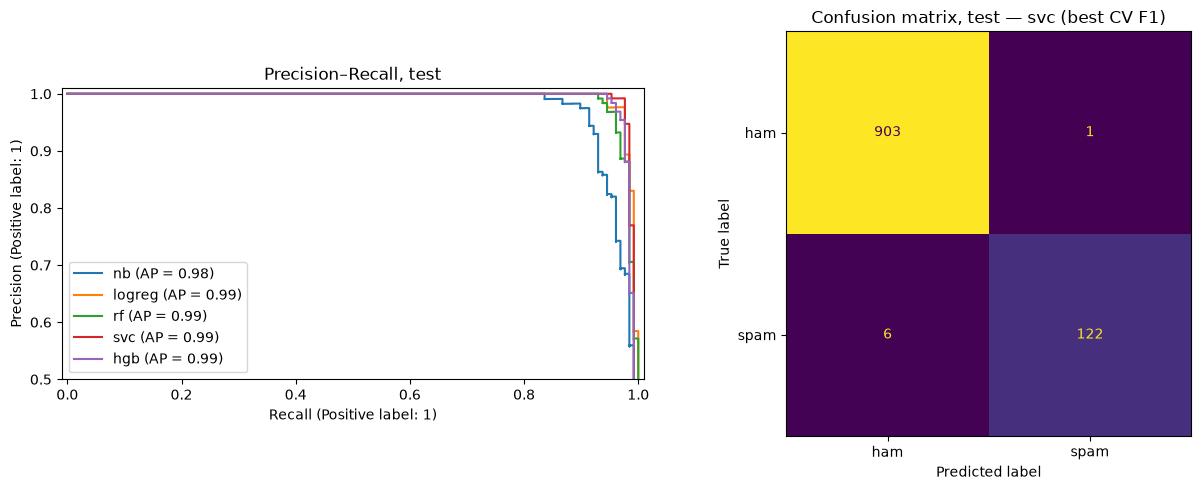

In [14]:
BEST = cv_res.cv_f1.idxmax()  # chosen by CV, not by test
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name in search:
    PrecisionRecallDisplay.from_predictions(y_te, pred[f"score_{name}"], name=name, ax=ax[0])
ax[0].set(title="Precision–Recall, test", ylim=(0.5, 1.01))
ConfusionMatrixDisplay.from_estimator(search[BEST], X_te, y_te, display_labels=["ham", "spam"], ax=ax[1], colorbar=False)
ax[1].set_title(f"Confusion matrix, test — {BEST} (best CV F1)")
plt.tight_layout(); plt.show()

### 1.8 Over- and underfitting

For each tuned model we compare F1 on the data it was fitted on (train+val), the 5-fold CV estimate and the held-out test set. A large train–CV gap means overfitting; low scores everywhere would mean underfitting.

In [15]:
gen = pd.DataFrame({
    "train_f1": {m: f1_score(y_trva, est.predict(X_trva)) for m, est in search.items()},
    "cv_f1": cv_res.cv_f1,
    "test_f1": test_res.f1.drop(["dummy_most_frequent", "dummy_stratified"]),
}).round(4)
gen["train_minus_cv"] = (gen.train_f1 - gen.cv_f1).round(4)
gen.sort_values("test_f1", ascending=False)

,train_f1,cv_f1,test_f1,train_minus_cv
svc,1.0000,0.9551,0.9721,0.0449
logreg,1.0000,0.9532,0.9680,0.0468
rf,0.9912,0.9473,0.9600,0.0439
hgb,1.0000,0.9504,0.9593,0.0496
nb,0.9803,0.9457,0.9360,0.0346


All models fit train+val almost perfectly (F1 0.98–1.00), and CV F1 is 0.035–0.05 lower. With thousands of sparse text features a linear model can separate its training set, so some gap is expected. Test F1 is close to CV F1 for every model (NB is 0.01 lower, the rest are higher), which supports generalization within this split. The high training scores show little evidence of underfitting on this corpus. Most errors are missed spam, so recall limits the score more than precision does.

### 1.9 Most important features

LogReg coefficients, NB log-probability ratio log P(token|spam) − log P(token|ham), and RF impurity importances. The table is saved to `artifacts/participant1/top_features.csv` for the error analysis in Part 3.

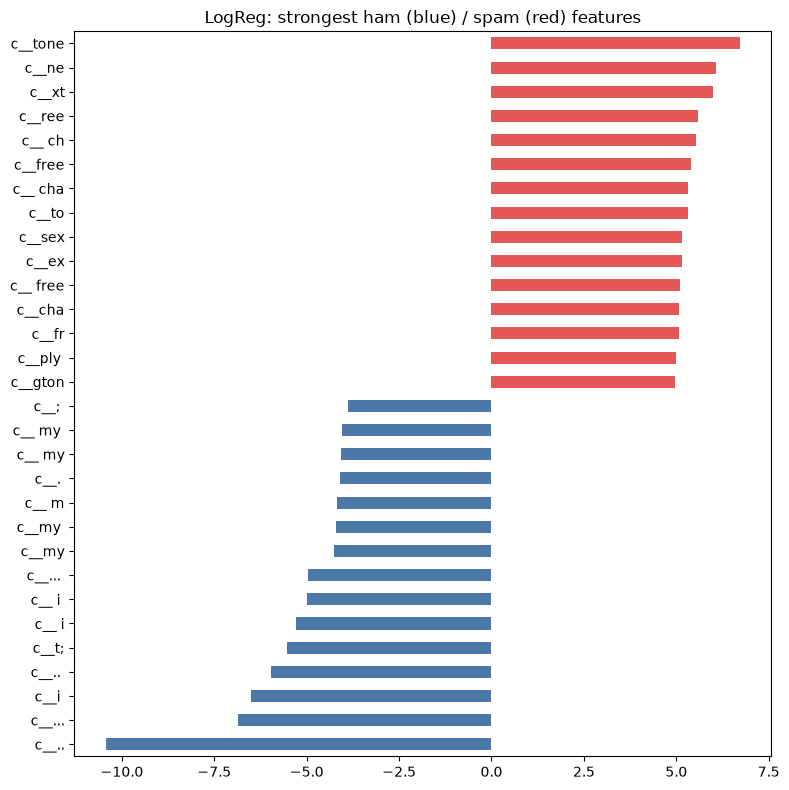

model,logreg,nb,rf
rank,,,
0,c__tone,w__claim,m__digit_ratio
1,c__ne,w__prize,m__n_digits
2,c__xt,w__call phonenum,w__phonenum
3,c__ree,w__phonenum num,m__has_phone
4,c__ ch,w__tone,m__n_chars
5,c__free,w__phonenum,m__upper_ratio
6,c__ cha,w__nokia,w__num
7,c__to,w__num cash,m__n_words
8,c__sex,w__rington,w__num num


In [16]:
def names(est): return est.named_steps["ct"].get_feature_names_out()

lr, nb, rf = search["logreg"], search["nb"], search["rf"]
nb_clf = nb.named_steps["clf"]
parts = {
    "logreg": pd.Series(lr.named_steps["clf"].coef_[0], names(lr)),
    "nb": pd.Series(nb_clf.feature_log_prob_[1] - nb_clf.feature_log_prob_[0], names(nb)),
    "rf": pd.Series(rf.named_steps["clf"].feature_importances_, names(rf)),
}
top = pd.concat([s.nlargest(20).rename("weight").rename_axis("feature")
                 .reset_index().assign(model=m) for m, s in parts.items()])[["model", "feature", "weight"]]
top.to_csv(OUT / "top_features.csv", index=False)

coef = parts["logreg"]
pd.concat([coef.nsmallest(15), coef.nlargest(15)[::-1]]).plot.barh(figsize=(8, 8), color=["#4C78A8"] * 15 + ["#E45756"] * 15,
                                                     title="LogReg: strongest ham (blue) / spam (red) features")
plt.tight_layout(); plt.show()
top.assign(rank=top.groupby("model").cumcount()).pivot(index="rank", columns="model", values="feature")

### 1.10 Prediction for new messages

The selected model (`BEST`, best CV F1) is a single pipeline, so raw text goes in and a label comes out: cleaning, meta-features and vectorisation happen inside. For LinearSVC the score is the signed distance to the decision boundary (above 0 means spam); LogReg gives a probability for comparison.

In [17]:
def predict_sms(texts, model=BEST):
    t = pd.Series(texts)
    X_new = pd.concat([pd.DataFrame({"text": t, "clean": t.map(clean_text)}), meta_features(t)], axis=1)
    est = search[model]
    return pd.DataFrame({
        "text": t,
        "prediction": np.where(est.predict(X_new) == 1, "spam", "ham"),
        f"{model}_score": est.decision_function(X_new) if model == "svc" else est.predict_proba(X_new)[:, 1],
        "logreg_p_spam": search["logreg"].predict_proba(X_new)[:, 1],
    }).round(3)

predict_sms([
    "Hey, are we still meeting at 7 tonight? I'll bring the notes",
    "URGENT! You have won a £1000 prize. Call 09061701461 now to claim, T&C apply",
    "Your parcel is waiting. Confirm delivery at www.parcel-track.com",
])

,text,prediction,svc_score,logreg_p_spam
0,"Hey, are we still meeting at 7 tonight? I'll b...",ham,-1.120,0.000
1,URGENT! You have won a £1000 prize. Call 09061...,spam,2.167,1.000
2,Your parcel is waiting. Confirm delivery at ww...,ham,-0.554,0.158


The personal message and the prize scam are classified correctly. Both models call the parcel phishing message `ham` (LogReg spam probability 0.16): it has no prize, currency or phone number. Delivery does come up in the 2011–2012 spam (24 messages), but 23 of those 24 include a phone number of 5+ digits, so the models learned the number, not the topic. This is the sampling bias from 1.3.

### 1.11 Part 1 conclusions

Numbers are taken from `repr_res`, `cv_res` and `test_res` above.

- 415 duplicates removed (exact after lower-casing and collapsing whitespace) (5,574 → 5,159), with no label conflicts. The shared split is 3,611 / 516 / 1,032 messages, 12.4–12.5% spam in each.
- Character 2–5-grams beat word features (CV F1 0.962 vs 0.944 with the same LogReg), probably because they keep misspelled spam words and short codes intact. Adding words to characters did not help.
- Baselines: always predicting `ham` gives F1 0; random guessing with the class shares gives F1 0.22 and PR-AUC 0.14. All trained models are far above both.
- On test, LinearSVC (F1 0.972, Precision 0.992) and LogReg (F1 0.968, Precision 0.992, PR-AUC 0.994, the best) lead. Linear SVM was also the best model in Almeida et al. (2011). CV picked weak regularisation for both (C = 10 and 1000). RF and HGB reach about 0.96. Multinomial NB is last at 0.936, with the lowest recall (0.914) and precision (0.959).
- HGB uses only the 9 meta-features and a 100-d SVD of the text and still reaches F1 0.959 with no false positives. The top RF importances are digit ratio, digit count, the `phonenum` token and `has_phone`. 72% of train spam contains a number with 5 or more digits, against 0.1% of ham.
- Train F1 is 0.98–1.00 and CV F1 is 0.035–0.05 lower, while test F1 matches CV. The models overfit train somewhat, yet hold up on test (section 1.8).
- 6 of 128 test spam messages share a digit-masked template with train/val, so some template leakage remains. Most errors are missed spam (recall 0.91–0.95); few ham messages are blocked. All models use the default threshold (0.5, or 0 for LinearSVC). Threshold tuning on `val` is left to Parts 2–3.
- New-style phishing without prizes or phone numbers (the parcel example in 1.10) is missed. Next steps: newer spam data, URL-domain features, threshold tuning on `val`.
- `artifacts/participant1/test_predictions.csv` has each model's scores on the shared test set for the team benchmark.

## Part 2 — Deep Learning & Transformers

We compare a 1D-CNN with trainable embeddings and a fully fine-tuned [BERT-Tiny](https://huggingface.co/google/bert_uncased_L-2_H-128_A-2) (two layers, hidden size 128). The models receive raw SMS text and use their own subword tokenization.

### 2.1 Shared data and class weights

We join the deduplicated corpus to Part 1's saved stratified split (70/10/20, seed 42). Only the training labels determine the weighted cross-entropy weights, using $w_c = N_{train}/(2N_c)$. This gives each class equal aggregate weight in the training objective.

In [18]:
from copy import deepcopy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    average_precision_score, f1_score, precision_recall_curve, precision_score, recall_score,
)
from tokenizers import Tokenizer, decoders, models, normalizers, pre_tokenizers, trainers
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup, set_seed

DL_SEED = 42
DL_MAX_LENGTH = 96
DL_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DL_OUT = Path("artifacts/participant2")
DL_OUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(4)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

sms = pd.read_csv("data/sms_dedup.csv").merge(
    pd.read_csv("artifacts/split.csv"), on="idx", how="outer", validate="one_to_one", indicator=True,
)
assert sms["_merge"].eq("both").all()
assert sms["split"].isin(["train", "val", "test"]).all()
assert sms["label"].isin(["ham", "spam"]).all() and sms["text"].notna().all()
sms["y"] = sms["label"].map({"ham": 0, "spam": 1})
dl_train, dl_val, dl_test = (sms.loc[sms["split"].eq(split)] for split in ("train", "val", "test"))

train_counts = np.bincount(dl_train["y"], minlength=2)
dl_weights = torch.tensor(len(dl_train) / (2 * train_counts), dtype=torch.float32, device=DL_DEVICE)
dl_loss = nn.CrossEntropyLoss(weight=dl_weights)
print(f"Device: {DL_DEVICE}; ham/spam training weights: {dl_weights.tolist()}")
sms.groupby("split")["y"].agg(messages="size", spam="sum", spam_share="mean")

/home/admin/ml_midterm/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu; ham/spam training weights: [0.571179986000061, 4.0122222900390625]


,messages,spam,spam_share
split,,,
test,1032,128,0.124031
train,3611,450,0.124619
val,516,64,0.124031


### 2.2 Subword tokenization

The CNN learns a byte-level BPE vocabulary on train only. BERT uses the pretrained tokenizer's fixed WordPiece vocabulary. Both cap sequences at 96 tokens. The table shows how often the cap truncates a training message. BERT uses its attention mask, and the CNN masks padded positions before max pooling.

In [19]:
cnn_tokenizer = Tokenizer(models.BPE())
cnn_tokenizer.normalizer = normalizers.Lowercase()
cnn_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
cnn_tokenizer.decoder = decoders.ByteLevel()
cnn_tokenizer.train_from_iterator(
    dl_train["text"],
    trainers.BpeTrainer(
        vocab_size=4_000, min_frequency=2, special_tokens=["[PAD]"],
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
        show_progress=False,
    ),
)
cnn_pad_id = cnn_tokenizer.token_to_id("[PAD]")

BERT_TINY = "google/bert_uncased_L-2_H-128_A-2"
BERT_REVISION = "30b0a37ccaaa32f332884b96992754e246e48c5f"
bert_tokenizer = AutoTokenizer.from_pretrained(BERT_TINY, revision=BERT_REVISION)
train_texts = dl_train["text"].tolist()
cnn_lengths = [len(tokens.ids) for tokens in cnn_tokenizer.encode_batch(train_texts)]
bert_lengths = bert_tokenizer(train_texts, truncation=False, return_length=True)["length"]
cnn_tokenizer.enable_truncation(max_length=DL_MAX_LENGTH)
cnn_tokenizer.enable_padding(length=DL_MAX_LENGTH, pad_id=cnn_pad_id, pad_token="[PAD]")


def cnn_inputs(texts):
    encoded = cnn_tokenizer.encode_batch(texts)
    return torch.tensor([tokens.ids for tokens in encoded], dtype=torch.long)


def bert_inputs(texts):
    encoded = bert_tokenizer(
        texts, padding="max_length", truncation=True, max_length=DL_MAX_LENGTH, return_tensors="pt",
    )
    return encoded["input_ids"], encoded["attention_mask"]


pd.DataFrame({
    "train_truncated": {name: int(np.sum(np.asarray(lengths) > DL_MAX_LENGTH))
                        for name, lengths in [("cnn", cnn_lengths), ("bert_tiny", bert_lengths)]},
})

,train_truncated
cnn,14
bert_tiny,15


### 2.3 Weighted training and validation threshold

For both models, AdamW updates all trainable parameters (weight decay 0.01, gradient clipping at norm 1.0). The CNN runs for up to 12 epochs (batch size 64, initial learning rate 0.002) and BERT-Tiny for up to eight (batch size 32, peak learning rate 0.0001). After each epoch we score validation messages and search all distinct validation scores for the threshold that maximizes spam F1. Ties favor higher precision, then the higher threshold. The best epoch by validation F1 (then precision) supplies both the weights and the threshold. Training stops after three epochs without improvement. We use the selected pair for final test inference.

In [20]:
def choose_spam_threshold(y_true, spam_scores):
    precision, recall, thresholds = precision_recall_curve(y_true, spam_scores)
    # The last precision/recall pair has no threshold.
    precision, recall = precision[:-1], recall[:-1]
    total = precision + recall
    f1 = np.divide(2 * precision * recall, total, out=np.zeros_like(total), where=total > 0)
    best = np.lexsort((thresholds, precision, f1.round(12)))[-1]
    return float(thresholds[best]), float(f1[best]), float(precision[best])


def sms_logits(model, batch_inputs):
    output = model(*(tensor.to(DL_DEVICE) for tensor in batch_inputs))
    return output if isinstance(output, torch.Tensor) else output.logits


@torch.inference_mode()
def predict_sms_logits(model, inputs, batch_size=64):
    model.eval()
    loader = DataLoader(TensorDataset(*inputs), batch_size=batch_size)
    return torch.cat([sms_logits(model, batch).cpu() for batch in loader])


def spam_scores(model, inputs):
    return predict_sms_logits(model, inputs).softmax(dim=1)[:, 1].numpy()


def fit_sms_model(model, encode, *, epochs, batch_size, learning_rate, warmup_fraction=0):
    model.to(DL_DEVICE)
    train_inputs = encode(dl_train["text"].tolist())
    val_inputs = encode(dl_val["text"].tolist())
    train_y = torch.tensor(dl_train["y"].to_numpy(), dtype=torch.long)
    val_y = torch.tensor(dl_val["y"].to_numpy(), dtype=torch.long)
    train_weight = dl_weights[train_y.to(DL_DEVICE)].sum()
    val_loss_fn = nn.CrossEntropyLoss(weight=dl_weights.cpu())
    loader = DataLoader(
        TensorDataset(*train_inputs, train_y), batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(DL_SEED),
    )
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0.01)
    steps = epochs * len(loader)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(steps * warmup_fraction), steps)
    history = []
    best_key = (-1.0, -1.0)
    stale_epochs = 0

    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum = torch.zeros((), device=DL_DEVICE)
        for *inputs, labels in loader:
            labels = labels.to(DL_DEVICE)
            optimizer.zero_grad()
            loss = dl_loss(sms_logits(model, inputs), labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            loss_sum += loss.detach() * dl_weights[labels].sum()

        val_logits = predict_sms_logits(model, val_inputs)
        scores = val_logits.softmax(dim=1)[:, 1].numpy()
        threshold, val_f1, val_precision = choose_spam_threshold(val_y.numpy(), scores)
        history.append({
            "epoch": epoch, "train_loss": (loss_sum / train_weight).item(),
            "val_loss": val_loss_fn(val_logits, val_y).item(),
            "val_f1": val_f1, "val_precision": val_precision, "threshold": threshold,
        })
        key = (round(val_f1, 12), val_precision)
        if key > best_key:
            best_key = key
            best_epoch = history[-1].copy()
            best_state = deepcopy(model.state_dict())
            stale_epochs = 0
        else:
            stale_epochs += 1
            if stale_epochs == 3:
                break

    model.load_state_dict(best_state)
    return best_epoch, pd.DataFrame(history).set_index("epoch")

### 2.4 1D-CNN with learned embeddings

The 64-dimensional embeddings feed convolutions with widths 3 and 5. ReLU activations feed masked global max pooling, which keeps the strongest activation from each channel. A dropout layer (0.30) and a linear classifier produce two logits.

In [21]:
class SmsCNN(nn.Module):
    def __init__(self, vocab_size, pad_id):
        super().__init__()
        self.pad_id = pad_id
        self.embedding = nn.Embedding(vocab_size, 64, padding_idx=pad_id)
        self.convs = nn.ModuleList(nn.Conv1d(64, 64, width, padding=width // 2) for width in (3, 5))
        self.classifier = nn.Sequential(nn.Dropout(0.30), nn.Linear(128, 2))

    def forward(self, input_ids):
        embedded = self.embedding(input_ids).transpose(1, 2)
        is_token = input_ids.ne(self.pad_id).unsqueeze(1)
        pooled = []
        for conv in self.convs:
            activations = conv(embedded).relu().masked_fill(~is_token, 0)
            pooled.append(activations.amax(dim=2))
        return self.classifier(torch.cat(pooled, dim=1))


def encode_cnn(texts):
    return (cnn_inputs(texts),)


set_seed(DL_SEED)
cnn_model = SmsCNN(cnn_tokenizer.get_vocab_size(), cnn_pad_id)
cnn_best, cnn_history = fit_sms_model(
    cnn_model, encode_cnn, epochs=12, batch_size=64, learning_rate=0.002,
)
cnn_history.round(4)

,train_loss,val_loss,val_f1,val_precision,threshold
epoch,,,,,
1,0.4837,0.1949,0.8837,0.8769,0.6730
2,0.1534,0.1013,0.9457,0.9385,0.7860
3,0.0565,0.0735,0.9606,0.9683,0.7756
4,0.0280,0.0662,0.9606,0.9683,0.8553
5,0.0135,0.0679,0.9606,0.9683,0.7700
6,0.0134,0.0669,0.9606,0.9683,0.7885


### 2.5 Fine-tuning BERT-Tiny

We initialize the encoder from Google's pretrained checkpoint, add a two-class classification head, and fine-tune the entire model. The learning rate warms up over the first 10% of planned steps, then decays linearly.

In [22]:
set_seed(DL_SEED)
bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_TINY, revision=BERT_REVISION, use_safetensors=True,
    num_labels=2, id2label={0: "ham", 1: "spam"}, label2id={"ham": 0, "spam": 1},
)
bert_best, bert_history = fit_sms_model(
    bert_model, bert_inputs, epochs=8, batch_size=32, learning_rate=1e-4, warmup_fraction=0.10,
)
bert_history.round(4)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-2_H-128_A-2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


,train_loss,val_loss,val_f1,val_precision,threshold
epoch,,,,,
1,0.4458,0.1384,0.9841,1.0000,0.6842
2,0.1394,0.0925,0.9841,1.0000,0.9762
3,0.0795,0.0910,0.9688,0.9688,0.9709
4,0.0525,0.0906,0.9688,0.9688,0.9836


### 2.6 Neural learning curves

Training loss is averaged over the updates made during each epoch. Validation loss is measured at the end of each epoch, in evaluation mode, using weights estimated on train. The vertical lines mark the checkpoints selected by spam F1 on validation. Validation loss measures the quality of the full score distribution, while F1 measures decisions at a selected threshold.

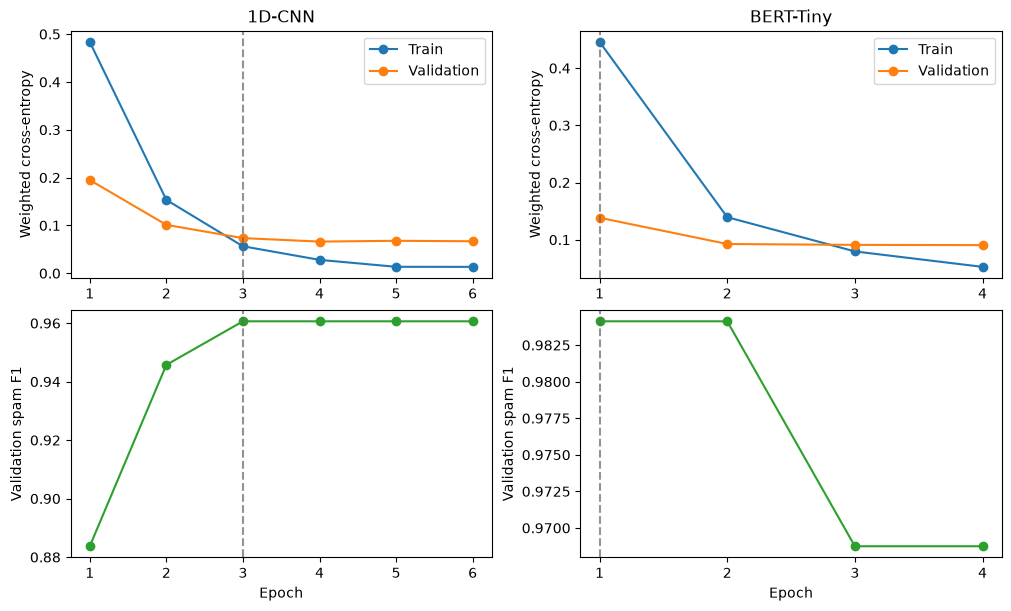

In [23]:
import matplotlib.pyplot as plt

learning_fig, learning_axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
for col, (name, history, selected) in enumerate([
    ("1D-CNN", cnn_history, cnn_best), ("BERT-Tiny", bert_history, bert_best),
]):
    loss_ax, f1_ax = learning_axes[:, col]
    loss_ax.plot(history.index, history["train_loss"], "o-", label="Train")
    loss_ax.plot(history.index, history["val_loss"], "o-", label="Validation")
    loss_ax.set(title=name, ylabel="Weighted cross-entropy")
    loss_ax.legend()
    f1_ax.plot(history.index, history["val_f1"], "o-", color="tab:green")
    f1_ax.set(xlabel="Epoch", ylabel="Validation spam F1")
    for axis in (loss_ax, f1_ax):
        axis.axvline(selected["epoch"], color="0.4", linestyle="--", alpha=0.7)
        axis.set_xticks(history.index)
plt.show()

### 2.7 Held-out test and benchmark exports

Both models use the same test IDs as Part 1. The main results use thresholds chosen on validation. The 0.5 rows give a reference for how tuning affected the precision/recall trade-off. PR-AUC is reported as average precision, as in Part 1. Scores are softmax outputs from class-weighted models.

In [24]:
dl_models = {
    "cnn": (cnn_model, encode_cnn, cnn_best),
    "bert_tiny": (bert_model, bert_inputs, bert_best),
}
dl_predictions = dl_test[["idx", "y"]].rename(columns={"y": "y_true"}).reset_index(drop=True)
dl_rows = []
for name, (model, encode, best_epoch) in dl_models.items():
    scores = spam_scores(model, encode(dl_test["text"].tolist()))
    dl_predictions[f"score_{name}"] = scores
    dl_predictions[f"pred_{name}"] = (scores >= best_epoch["threshold"]).astype(int)
    for setting, threshold in [("val_tuned", best_epoch["threshold"]), ("default", 0.5)]:
        predicted = scores >= threshold
        y_true = dl_predictions["y_true"]
        dl_rows.append({
            "model": name, "setting": setting,
            "epoch": best_epoch["epoch"], "threshold": threshold, "val_f1": best_epoch["val_f1"],
            "precision": precision_score(y_true, predicted, zero_division=0),
            "recall": recall_score(y_true, predicted, zero_division=0),
            "f1": f1_score(y_true, predicted, zero_division=0),
            "pr_auc": average_precision_score(y_true, scores),
        })

dl_results = pd.DataFrame(dl_rows)
dl_predictions.to_csv(DL_OUT / "test_predictions.csv", index=False, float_format="%.9g")
dl_results.loc[dl_results["setting"].eq("val_tuned")].to_csv(
    DL_OUT / "test_metrics.csv", index=False, float_format="%.9g",
)
dl_results.set_index(["model", "setting"]).round(4)

epoch  threshold  val_f1  precision  recall      f1  \
model     setting                                                          
cnn       val_tuned      3     0.7756  0.9606     0.9667  0.9062  0.9355   
          default        3     0.5000  0.9606     0.8571  0.9375  0.8955   
bert_tiny val_tuned      1     0.6842  0.9841     0.9828  0.8906  0.9344   
          default        1     0.5000  0.9841     0.9746  0.8984  0.9350   

                     pr_auc  
model     setting            
cnn       val_tuned  0.9776  
          default    0.9776  
bert_tiny val_tuned  0.9741  
          default    0.9741

### 2.8 Part 2 conclusions

- CNN validation F1 improves from 0.884 to 0.961 by epoch 3, then stays flat while training loss falls from 0.056 to 0.013. Early epochs show weaker fit, and later epochs mostly improve training fit. BERT validation F1 peaks at 0.984 in epochs 1–2 and drops to 0.969 by epoch 3 even as validation loss falls. This illustrates why the checkpoint is selected by spam F1 rather than by weighted loss.
- With the threshold selected on validation, the CNN reaches test F1 **0.9355** and precision **0.9667**. BERT-Tiny reaches F1 **0.9344** and precision **0.9828**. BERT flags 2 legitimate messages and misses 14 spam messages. The CNN flags 4 and misses 12.
- Compared with the 0.5 cutoff, tuning raises test precision for both models and reduces recall. CNN test F1 rises from 0.8955 to 0.9355. BERT test F1 stays close to 0.935. Its stronger validation F1 does not carry over to the held-out test.
- Part 1's LinearSVC reaches test F1 0.972 on these same IDs. Both neural models use raw text with a 96-token cap, and the classical models are fitted on train+val. The benchmark reflects these different training setups.

## Part 3 — Evaluation, Error Analysis & Demo

### 3.1 Shared benchmark

We join both prediction files on the 1,032 shared test IDs and verify their labels against the saved dataset and split. Precision, Recall and F1 treat spam as positive. PR-AUC is average precision over the raw scores. Classical models keep their default decisions (0 for the LinearSVC margin and 0.5 for probabilities). Neural models use the exported validation thresholds. The dummy baselines are fitted on train+val with seed 42, matching Part 1.

In [25]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    PrecisionRecallDisplay, average_precision_score, confusion_matrix,
    f1_score, precision_score, recall_score,
)

p3_out = Path("artifacts/participant3")
p3_out.mkdir(parents=True, exist_ok=True)
p3_data = pd.read_csv("data/sms_dedup.csv").merge(
    pd.read_csv("artifacts/split.csv"), on="idx", validate="one_to_one",
)
p3_data["y_true"] = p3_data["label"].map({"ham": 0, "spam": 1})
p3_test = p3_data.loc[p3_data["split"].eq("test"), ["idx", "y_true", "text"]].set_index("idx")

for participant in ("participant1", "participant2"):
    exported = pd.read_csv(Path("artifacts") / participant / "test_predictions.csv").set_index("idx")
    assert p3_test.index.is_unique and exported.index.is_unique
    assert p3_test.index.difference(exported.index).empty
    assert exported.index.difference(p3_test.index).empty
    pd.testing.assert_series_equal(p3_test["y_true"], exported["y_true"].reindex(p3_test.index))
    p3_test = p3_test.join(exported.drop(columns="y_true"))

p3_thresholds = pd.read_csv("artifacts/participant2/test_metrics.csv").set_index("model")["threshold"]
p3_models = {
    "nb": "Multinomial NB", "logreg": "Logistic Regression", "rf": "Random Forest",
    "svc": "LinearSVC", "hgb": "HistGradientBoosting", "cnn": "1D-CNN", "bert_tiny": "BERT-Tiny",
}
p3_classical_cutoffs = {"nb": 0.5, "logreg": 0.5, "rf": 0.5, "svc": 0.0, "hgb": 0.5}
for name, cutoff in p3_classical_cutoffs.items():
    p3_test[f"pred_{name}"] = (p3_test[f"score_{name}"] >= cutoff).astype(int)

p3_train_val = p3_data.loc[p3_data["split"].isin(["train", "val"]), "y_true"]
for strategy, label in [("most_frequent", "Dummy (always ham)"), ("stratified", "Dummy (stratified)")]:
    name = f"dummy_{strategy}"
    baseline = DummyClassifier(strategy=strategy, random_state=42).fit(
        np.zeros((len(p3_train_val), 1)), p3_train_val,
    )
    p3_dummy_input = np.zeros((len(p3_test), 1))
    p3_test[f"pred_{name}"] = baseline.predict(p3_dummy_input)
    p3_test[f"score_{name}"] = baseline.predict_proba(p3_dummy_input)[:, 1]
    p3_models[name] = label

p3_rows = []
p3_y = p3_test["y_true"]
for name, label in p3_models.items():
    predicted = p3_test[f"pred_{name}"]
    scores = p3_test[f"score_{name}"]
    _, fp, fn, _ = confusion_matrix(p3_y, predicted, labels=[0, 1]).ravel()
    p3_rows.append({
        "model": label,
        "precision": precision_score(p3_y, predicted, zero_division=0),
        "recall": recall_score(p3_y, predicted, zero_division=0),
        "f1": f1_score(p3_y, predicted, zero_division=0),
        "pr_auc": average_precision_score(p3_y, scores),
        "fp": fp, "fn": fn,
    })

p3_benchmark = pd.DataFrame(p3_rows).sort_values("f1", ascending=False).set_index("model")
p3_benchmark.to_csv(p3_out / "benchmark.csv", float_format="%.9g")
p3_benchmark.round(4)

,precision,recall,f1,pr_auc,fp,fn
model,,,,,,
LinearSVC,0.9919,0.9531,0.9721,0.9920,1,6
Logistic Regression,0.9918,0.9453,0.9680,0.9939,1,7
Random Forest,0.9836,0.9375,0.9600,0.9913,2,8
HistGradientBoosting,1.0000,0.9219,0.9593,0.9904,0,10
Multinomial NB,0.9590,0.9141,0.9360,0.9784,5,11
1D-CNN,0.9667,0.9062,0.9355,0.9776,4,12
BERT-Tiny,0.9828,0.8906,0.9344,0.9741,2,14
Dummy (stratified),0.2117,0.2266,0.2189,0.1439,108,99
Dummy (always ham),0.0000,0.0000,0.0000,0.1240,0,128


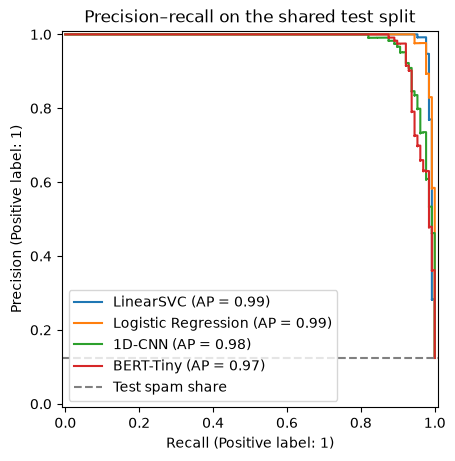

In [26]:
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
for name in ("svc", "logreg", "cnn", "bert_tiny"):
    PrecisionRecallDisplay.from_predictions(
        p3_y, p3_test[f"score_{name}"], name=p3_models[name], ax=ax,
    )
ax.axhline(p3_y.mean(), color="gray", linestyle="--", label="Test spam share")
ax.set_title("Precision–recall on the shared test split")
ax.legend(loc="lower left")
plt.show()

LinearSVC leads on test F1, logistic regression leads on average precision, and HistGradientBoosting makes zero false-positive decisions at its tested cutoff. The benchmark uses the original training protocols. Classical models fit train+val, while neural models fit train and use val to choose checkpoints and thresholds. Treat the comparison as a benchmark of these trained systems on this corpus. The test set contains 128 spam messages, so a few decision changes affect the ranking.

In [27]:
template_key = (
    p3_data.set_index("idx")["text"].str.lower().str.split().str.join(" ")
    .str.replace(r"\d", "0", regex=True)
)
seen_templates = set(template_key.loc[p3_data.loc[p3_data["split"].isin(["train", "val"]), "idx"]])
unseen_template = ~template_key.reindex(p3_test.index).isin(seen_templates)
print(f"Excluded {(~unseen_template).sum()} of {len(p3_test)} test messages with a detected overlap.")
pd.DataFrame({
    "all_test_f1": {p3_models[name]: f1_score(p3_y, p3_test[f"pred_{name}"]) for name in ("svc", "cnn", "bert_tiny")},
    "unseen_template_f1": {
        p3_models[name]: f1_score(p3_y[unseen_template], p3_test.loc[unseen_template, f"pred_{name}"])
        for name in ("svc", "cnn", "bert_tiny")
    },
}).round(4)

Excluded 6 of 1032 test messages with a detected overlap.


,all_test_f1,unseen_template_f1
LinearSVC,0.9721,0.9707
1D-CNN,0.9355,0.9322
BERT-Tiny,0.9344,0.9310


This sensitivity check uses the existing predictions and removes messages that match a lowercased, whitespace-normalized, digit-masked template in train or validation. All six excluded messages are spam. LinearSVC stays ahead at F1 0.971 and the two neural models remain close at 0.932 and 0.931. The check leaves the selected models and thresholds fixed. A broader campaign-grouped or later-in-time split would give stronger evidence about deployment.

### 3.2 What the classical models learned

The table lists the five strongest spam-associated features per model. Logistic regression ranks signed coefficients, Multinomial NB ranks spam-vs-ham log probability ratios, and Random Forest ranks impurity importances. Each ranking uses its own scale. Forest importances rank predictive features and carry no class direction.

In [28]:
p3_top = pd.read_csv("artifacts/participant1/top_features.csv")
p3_feature_names = {name: p3_models[name] for name in ("logreg", "nb", "rf")}
p3_top_five = p3_top.groupby("model", sort=False).head(5).reset_index(drop=True)
p3_top_five.assign(model=p3_top_five["model"].map(p3_feature_names))

,model,feature,weight
0,Logistic Regression,c__tone,6.715258
1,Logistic Regression,c__ne,6.073316
2,Logistic Regression,c__xt,5.987894
3,Logistic Regression,c__ree,5.594583
4,Logistic Regression,c__ ch,5.535284
5,Multinomial NB,w__claim,5.901013
6,Multinomial NB,w__prize,5.779453
7,Multinomial NB,w__call phonenum,5.740531
8,Multinomial NB,w__phonenum num,5.730046
9,Multinomial NB,w__tone,5.591545


Logistic regression ranks fragments such as `tone` and `xt` highly. They can occur in ringtone offers and reply instructions. NB highlights `claim`, `prize` and `call phonenum`. The forest relies strongly on digits, phone indicators and numeric placeholders.

### 3.3 False positives and false negatives

We inspect LinearSVC, the reported F1 leader, and BERT-Tiny, the model used in the demo. The examples are selected from labeled test errors for qualitative analysis. The explanations describe cues in the messages and possible failure modes.

In [29]:
p3_cases = [
    ("svc", 1618, "Short benign reply. Its SVC margin is barely above the default boundary."),
    ("svc", 3228, "Asks for age and gender in a short reply format and resembles a normal signup message."),
    ("svc", 4979, "Conversational report about unsolicited texts. The spam label is ambiguous from the text alone."),
    ("bert_tiny", 1165, "Legitimate transaction notification with amounts and templated reference fields."),
    ("bert_tiny", 1926, "Free-content promotion uses casual language and refers to a link in another SMS."),
    ("bert_tiny", 2768, "Subscription message mentions cancellation and HELP. It reads like a service notice."),
]

p3_examples = []
for name, idx, observation in p3_cases:
    row = p3_test.loc[idx]
    truth, prediction = int(row["y_true"]), int(row[f"pred_{name}"])
    if truth == prediction:
        continue
    p3_examples.append({
        "model": p3_models[name], "idx": idx, "error": "FP" if prediction else "FN",
        "score": row[f"score_{name}"], "text": row["text"], "observation": observation,
    })
p3_errors = pd.DataFrame(p3_examples, columns=["model", "idx", "error", "score", "text", "observation"])
p3_errors.to_csv(p3_out / "error_examples.csv", index=False, float_format="%.9g")
with pd.option_context("display.max_colwidth", None):
    display(p3_errors.round({"score": 4}))

,model,idx,error,score,text,observation
0,LinearSVC,1618,FP,0.0183,Glad to see your reply.,Short benign reply. Its SVC margin is barely above the default boundary.
1,LinearSVC,3228,FN,-0.0857,Welcome! Please reply with your AGE and GENDER to begin. e.g 24M,Asks for age and gender in a short reply format and resembles a normal signup message.
2,LinearSVC,4979,FN,-0.7210,dating:i have had two of these. Only started after i sent a text to talk sport radio last week. Any connection do you think or coincidence?,Conversational report about unsolicited texts. The spam label is ambiguous from the text alone.
3,BERT-Tiny,1165,FP,0.6854,NEFT Transaction with reference number &lt;#&gt; for Rs. &lt;DECIMAL&gt; has been credited to the beneficiary account on &lt;#&gt; at &lt;TIME&gt; : &lt;#&gt;,Legitimate transaction notification with amounts and templated reference fields.
4,BERT-Tiny,1926,FN,0.1024,TheMob>Yo yo yo-Here comes a new selection of hot downloads for our members to get for FREE! Just click & open the next link sent to ur fone...,Free-content promotion uses casual language and refers to a link in another SMS.
5,BERT-Tiny,2768,FN,0.4912,Sorry! U can not unsubscribe yet. THE MOB offer package has a min term of 54 weeks> pls resubmit request after expiry. Reply THEMOB HELP 4 more info,Subscription message mentions cancellation and HELP. It reads like a service notice.


Messages can need sender, conversation, and campaign context that a text-only classifier lacks. The corpus reflects older English-language SMS and contains similar templates across splits after exact deduplication. Performance on current campaigns, other languages, and unseen templates needs separate validation. BERT also truncates SMS at 96 tokens and its class-weighted softmax output is uncalibrated.

### 3.4 Streamlit demo

The demo uses BERT-Tiny because it returns a spam probability and its validation-tuned operating point protects precision. The cell below predicts three fresh examples without a separate app. It then exports the same trained checkpoint for the optional Streamlit demo.

The probability is the model's softmax score. The cutoff selected on validation turns it into a label. The example domain is reserved for documentation.

In [30]:
demo_messages = [
    "Could you bring my notebook to class tomorrow?",
    "Win a cash prize! Text CLAIM to 81234 now. Charges apply.",
    "Package delivery failed. Update your address at https://delivery.example/confirm",
]
demo_scores = spam_scores(bert_model, bert_inputs(demo_messages))
demo_threshold = bert_best["threshold"]
display(pd.DataFrame({
    "new_sms": demo_messages,
    "prediction": np.where(demo_scores >= demo_threshold, "spam", "ham"),
    "spam_probability": demo_scores,
}).round({"spam_probability": 4}))

demo_dir = p3_out / "demo_model"
demo_dir.mkdir(exist_ok=True)
bert_model.save_pretrained(demo_dir, safe_serialization=True)
bert_tokenizer.save_pretrained(demo_dir)
(demo_dir / "inference.json").write_text(json.dumps({
    "max_length": DL_MAX_LENGTH,
    "threshold": bert_best["threshold"],
}, indent=2) + "\n")
print(f"Demo checkpoint exported to {demo_dir}")

,new_sms,prediction,spam_probability
0,Could you bring my notebook to class tomorrow?,ham,0.0855
1,Win a cash prize! Text CLAIM to 81234 now. Cha...,spam,0.7650
2,Package delivery failed. Update your address a...,spam,0.7847


Demo checkpoint exported to artifacts/participant3/demo_model


### References and AI assistance

- Almeida, T., & Hidalgo, J. (2011). [SMS Spam Collection](https://doi.org/10.24432/C5CC84). UCI Machine Learning Repository, CC BY 4.0.
- Almeida, T. A., Gómez Hidalgo, J. M., & Yamakami, A. (2011). *Contributions to the Study of SMS Spam Filtering: New Collection and Results*. DocEng 2011.
- Gómez Hidalgo, J. M., Almeida, T. A., & Yamakami, A. (2012). *On the Validity of a New SMS Spam Collection*. ICMLA.
- Turc, I., Chang, M.-W., Lee, K., & Toutanova, K. (2019). *Well-Read Students Learn Better: On the Importance of Pre-training Compact Models*. [Google BERT-Tiny checkpoint](https://huggingface.co/google/bert_uncased_L-2_H-128_A-2).
- Implementation uses scikit-learn, NLTK, pandas, Matplotlib, PyTorch, and Hugging Face Transformers and Tokenizers. Package versions and run commands are in the repository README and requirements files.
- Claude Code (Anthropic) assisted with Part 1. Codex (OpenAI) assisted with Parts 2–3, notebook integration, verification, and slides.